# 01 — The event log, the process and its controls

**Source:** [BPI Challenge 2019](https://doi.org/10.4121/uuid:d06aff4b-79f0-45e6-8ec8-e19730c248f1)
(van Dongen, 4TU.ResearchData, CC BY 4.0): the purchase-order handling of a multinational coatings
and paints company, as recorded by its ERP. Vendors and users are anonymised.

**Goal:** learn how the log really behaves before modelling it. Each surprise below changed a
design decision later on. One of them, the value field, would have produced badly wrong numbers.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

from p2p import config

con = duckdb.connect(str(config.DB_PATH), read_only=True)
q = lambda sql: con.execute(sql).df()  # noqa: E731

COBALT, AMBER, TEAL, GREY = "#5A6CF0", "#E39B2D", "#2BB39E", "#8A93A3"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 90)


def save(fig, name):
    fig.savefig(config.FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Shape of the log
Each purchase order line is a *case*, and each case is a sequence of timestamped ERP events.

In [2]:
q("""select count(*) lines, count(distinct document_id) documents, count(distinct vendor_id) vendors,
            count(distinct company_id) companies, sum(n_events) events, sum(order_value_eur) order_value_eur
     from fct_po_items""")

,lines,documents,vendors,companies,events,order_value_eur
0,251734,76349,1975,4,1595923.0,996818747.0


In [3]:
q("""select item_category, flow, count(*) lines, sum(order_value_eur) order_value_eur, avg(n_events) avg_events
     from fct_po_items group by 1, 2 order by lines desc""")

,item_category,flow,lines,order_value_eur,avg_events
0,"3-way match, invoice before GR",three_way_before_gr,221010,783697142.0,5.586661
1,"3-way match, invoice after GR",three_way_after_gr,15182,199908447.0,21.027072
2,Consignment,consignment,14498,0.0,2.488895
3,2-way match,two_way,1044,13213158.0,5.649425


Four matching flows, each with its own rules, so one conformance model can't describe all of
them. One company holds nearly every line, so "company" is not a useful feature.

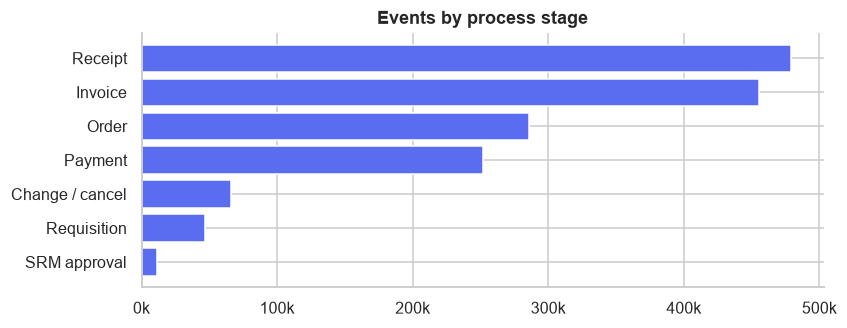

In [4]:
d = q("""select process_stage, sum(n_events) events from dim_activity group by 1 order by 2""")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(d["process_stage"], d["events"], color=COBALT)
ax.set_title("Events by process stage")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}k"))
save(fig, "eda_events_by_stage")

## 2. Surprises, and what each one changed

**Timestamps.** A few events are dated as far back as 1948, and activity stops abruptly on
18 January 2019. Implausible dates are flagged rather than deleted, and 18 January becomes the
censoring date: items open then have an unknown end, not a missing one.

In [5]:
q("""select strftime(event_ts, '%Y-%m') as year_month, count(*) events, avg(is_valid_ts::int) valid_share
     from fct_item_events where event_ts >= date '2018-11-01' group by 1 order by 1""")

,year_month,events,valid_share
0,2018-11,142316,1.0
1,2018-12,99908,1.0
2,2019-01,45128,1.0
3,2019-02,2,0.0
4,2019-04,2,0.0
5,2019-10,1,0.0
6,2019-12,2,0.0
7,2020-04,2,0.0


**"Duplicates" that aren't.** 132,748 events look like exact duplicates, but nine in ten are
service entry sheets posted in bulk within the same minute. Deleting them would remove real work,
so they stay.

**The value field is not what its name suggests.** This is the finding that mattered most.
`Cumulative net worth (EUR)` is the line's running value, repeated on every event.

In [6]:
q("""select activity, event_ts, net_value_eur from fct_item_events
     where item_id = (select item_id from fct_po_items
                      where n_clears = 3 and n_goods_receipts = 3 and item_type = 'Standard' and order_value_eur > 0
                      order by item_id limit 1)
     order by event_no""")

,activity,event_ts,net_value_eur
0,Create Purchase Order Item,2018-01-02 10:47:00,8812.0
1,Change Quantity,2018-02-08 12:59:00,8812.0
2,Record Goods Receipt,2018-03-14 19:35:00,8812.0
3,Vendor creates invoice,2018-03-15 22:59:00,8812.0
4,Record Goods Receipt,2018-03-23 14:25:00,8812.0
5,Record Invoice Receipt,2018-03-24 05:03:00,8812.0
6,Vendor creates invoice,2018-03-29 21:59:00,8812.0
7,Record Invoice Receipt,2018-04-05 09:08:00,8812.0
8,Vendor creates invoice,2018-04-13 21:59:00,8812.0
9,Vendor creates debit memo,2018-04-13 21:59:00,8812.0


Three receipts and three payments, all carrying the same figure, so these are not document
amounts. A first version summed them and reported about €5.7B of goods and invoices against a
€997M order book. **Value-based three-way matching is therefore not possible on this data.** The
rules test document *counts* instead, and exposure is always the order value.

## 3. How orderly is the process?

In [7]:
q("select * from analytics.variant_summary")

,flow,n_variants,n_items,top1_share,top10_share,singleton_variants
0,three_way_before_gr,7832,221010.0,0.216999,0.616728,5438
1,three_way_after_gr,4228,15182.0,0.153274,0.425175,3653
2,consignment,281,14498.0,0.605325,0.895641,164
3,two_way,148,1044.0,0.216475,0.703065,85


In [8]:
q("select * from analytics.straight_through")

,flow,n_paid,no_rework_rate,straight_through_rate,median_days_clean,median_days_rework
0,three_way_before_gr,173698,0.854713,0.837874,73.206250,88.484028
1,three_way_after_gr,9676,0.770256,0.719616,77.011111,79.178472
2,two_way,303,0.000000,0.000000,NaN,7.047222


There are about 12,000 distinct paths. The main flow is fairly disciplined: its ten commonest paths
cover 62% of lines. The GR-based flow is far looser, which also shows in conformance below.

In [9]:
q("select * from analytics.conformance")

,flow,cases_sampled,fitness,fitting_cases_pct,precision,places,transitions
0,three_way_before_gr,3000,0.955656,0.704000,0.968106,12,15
1,three_way_after_gr,3000,0.676654,0.491000,0.611311,11,13
2,two_way,1044,0.998556,0.988506,0.694646,13,12
3,consignment,3000,0.989248,0.921667,0.996536,8,12


Process models were discovered with the inductive miner from frequent paths, then replayed on a
sample. **Fitness** asks whether the model can reproduce what happened, and **precision** whether it
avoids allowing things that never happen. The GR-based flow scores markedly lower on both.

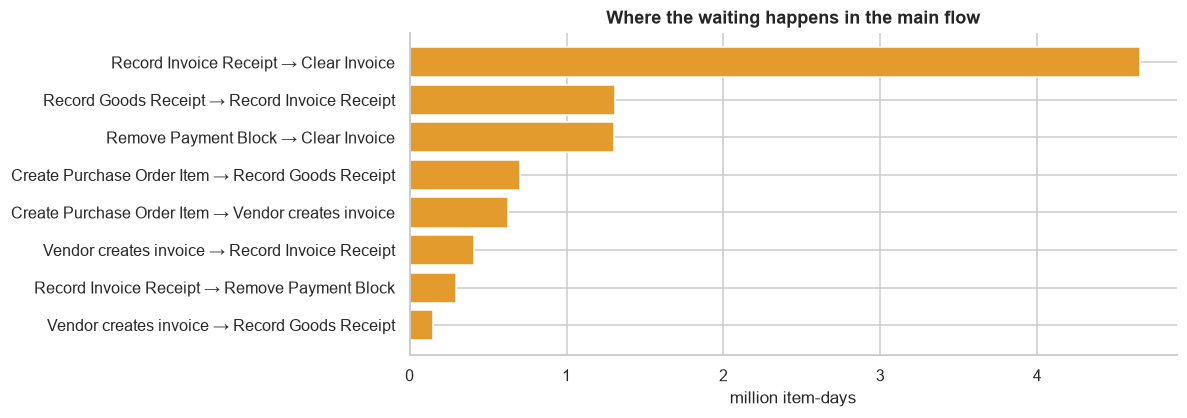

In [10]:
b = q("select * from analytics.bottlenecks order by item_days desc limit 8")
b["step"] = b["source_activity"] + " → " + b["target_activity"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(b["step"][::-1], b["item_days"][::-1] / 1e6, color=AMBER)
ax.set_xlabel("million item-days")
ax.set_title("Where the waiting happens in the main flow")
save(fig, "process_bottlenecks")

Waiting concentrates after the invoice is booked: *Record Invoice Receipt → Clear Invoice* alone
carries over three times the item-days of any other step. Much of this may simply be payment terms,
which the log doesn't contain, so it's a question to take to the business rather than a verdict.

## 4. Control testing

In [11]:
r = q("select label, definition, n_items, rate, value_at_risk_eur, n_open, n_vendors from analytics.rule_summary order by value_at_risk_eur desc nulls last")
r

,label,definition,n_items,rate,value_at_risk_eur,n_open,n_vendors
0,Segregation of duties,"Same person ordered and received, or booked and paid",7551,0.029996,120213881.0,1772,643
1,Price changed after invoice,Change Price after Record Invoice Receipt,2374,0.009431,87780826.0,32,415
2,After-the-fact purchase,Vendor invoice dated before the order existed,3502,0.013912,48053931.0,380,542
3,More payments than invoices,More Clear Invoice events than live invoices,4776,0.018972,31984962.0,0,523
4,More invoices than receipts,Paid item with more live invoices than goods receipts,1414,0.005617,11180363.0,0,290
5,Paid before goods arrived,Clear Invoice precedes any Goods Receipt,655,0.002602,1753787.0,0,102
6,Paid without a recorded invoice,Clear Invoice with no Record Invoice Receipt,384,0.001525,187777.0,0,37
7,Invoice before receipt (GR-based),GR-based flow booked invoice first,0,0.000000,NaN,0,0
8,Goods receipt on 2-way item,2-way item should not have a receipt,0,0.000000,NaN,0,0
9,Invoice on consignment item,Consignment items are invoiced separately,0,0.000000,NaN,0,0


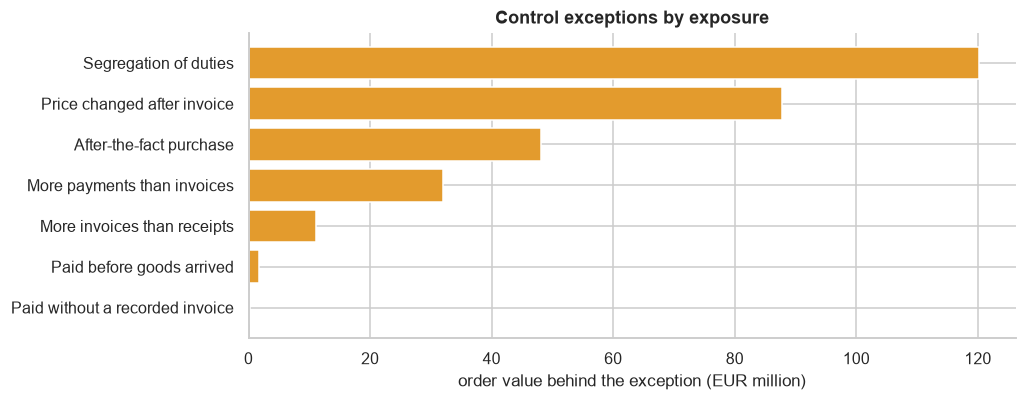

In [12]:
s = r[r["n_items"] > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(s["label"], s["value_at_risk_eur"] / 1e6, color=AMBER)
ax.set_xlabel("order value behind the exception (EUR million)")
ax.set_title("Control exceptions by exposure")
save(fig, "compliance_exposure")

* **Three controls recorded no exceptions**, including the GR-based block on invoices before
  receipt. That looks system-enforced, which is worth saying as plainly as the failures.
* **Goods receivers and payers are fully separate**: no user appears in both roles at all.
  So segregation of duties is tested on two other conflicts, ordering and receiving, and booking
  and paying.
* An exception is an indicator to review, not evidence of wrongdoing. Service items, for example,
  legitimately post many entries, which is why they're excluded from the receipt-count test.

In [13]:
con.close()